In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../terrawatch-datasets")     # the dataset folder (sits next to this repository)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 06. Labels and rows: what exactly is one sample?

One **row** = one forest cell on one day `t`. For that row we ask:

> *Will a satellite see a fire (inside the forest boundary) in this cell on day t + 1?*

The answer, 0 or 1, is the **label** `y_forest`. The cube holds what we know on day t. The label looks one day ahead.

In [2]:
rows = pd.read_parquet(f"{DS}/forest_all/rows.parquet")
print(len(rows), "rows")
rows[["cell_id", "t", "date_t", "label_date", "set", "split_t", "y_any", "y_forest", "ambiguous", "valid_primary"]].sample(6, random_state=1).sort_values("date_t")

18277436 rows


,cell_id,t,date_t,label_date,set,split_t,y_any,y_forest,ambiguous,valid_primary
16854177,288961,698,2020-11-29,2020-11-30,northeast,train,0,0,0,True
3233764,238818,704,2020-12-05,2020-12-06,six,train,0,0,0,True
5479966,210806,1194,2022-04-09,2022-04-10,six,train,0,0,0,True
10364870,190788,2259,2025-03-09,2025-03-10,six,test,0,0,0,True
11171279,242824,2434,2025-08-31,2025-09-01,six,test,0,0,0,True
13029854,152796,2506,2025-11-11,2025-11-12,D1,test,0,0,0,True


| column | meaning |
|---|---|
| `date_t` | the day whose data the model is allowed to see |
| `label_date` | the day we ask about (always the next day) |
| `y_any` | any fire detection in the cell on `label_date` |
| `y_forest` | at least one detection with its footprint inside the forest boundary (**the target we train on**) |
| `ambiguous` | `y_any = 1` but `y_forest = 0` (a fire in the cell, but not clearly in forest) |
| `valid_primary` | the row is used for training and scoring |
| `split_t` | `train`, `validation`, `test` (by date), or `none` |

## 1. Which rows are used

In [3]:
allr = len(rows)
v = rows.valid_row.sum()
print(f"all rows                           {allr:10d}")
print(f"- cell not usable that day         {allr - v:10d}   (no weather, or masked)")
print(f"- ambiguous (fire, not in forest)  {int(((rows.valid_row) & (rows.ambiguous == 1)).sum()):10d}")
print(f"= valid_primary (used)             {int(rows.valid_primary.sum()):10d}")
print(f"  of which fire days (y_forest=1)  {int(rows[rows.valid_primary].y_forest.sum()):10d}   = {100 * rows[rows.valid_primary].y_forest.mean():.1f}%")

all rows                             18277436
- cell not usable that day             271624   (no weather, or masked)
- ambiguous (fire, not in forest)      201109
= valid_primary (used)               17804703


  of which fire days (y_forest=1)      458358   = 2.6%


## 2. Fires over time and place

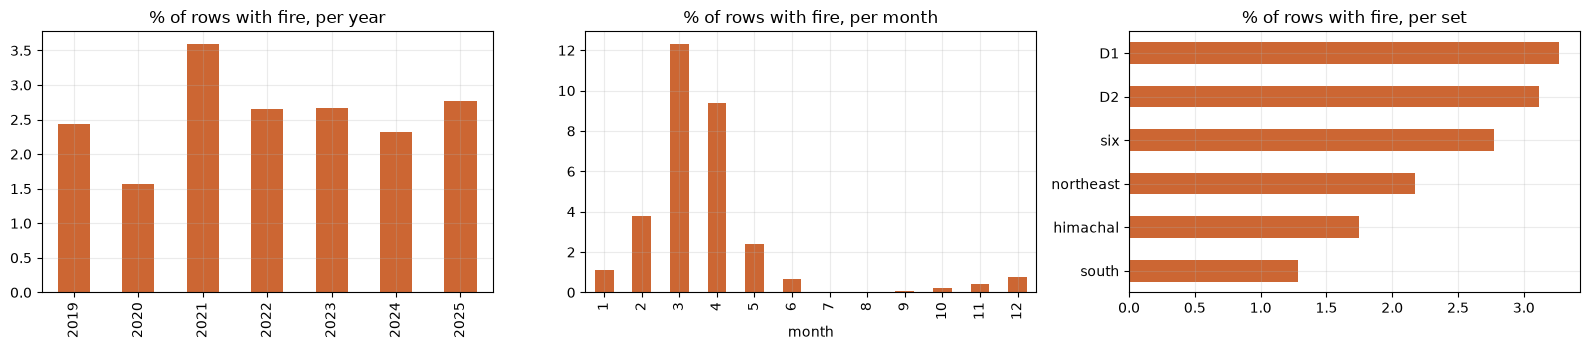

% of rows with fire, by month: {1: 1.11, 2: 3.8, 3: 12.32, 4: 9.4, 5: 2.39, 6: 0.65, 7: 0.04, 8: 0.03, 9: 0.05, 10: 0.22, 11: 0.43, 12: 0.75}


In [4]:
u = rows[rows.valid_primary]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
u.groupby(u.date_t.dt.year).y_forest.mean().mul(100).plot.bar(ax=ax[0], color="#c63"); ax[0].set_title("% of rows with fire, per year"); ax[0].set_xlabel("")
u.groupby(u.date_t.dt.month).y_forest.mean().mul(100).plot.bar(ax=ax[1], color="#c63"); ax[1].set_title("% of rows with fire, per month"); ax[1].set_xlabel("month")
u.groupby("set").y_forest.mean().mul(100).sort_values().plot.barh(ax=ax[2], color="#c63"); ax[2].set_title("% of rows with fire, per set"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()
m = u.groupby(u.date_t.dt.month).y_forest.mean().mul(100).round(2)
print("% of rows with fire, by month:", m.to_dict())

The chance of a fire depends hugely on the month (printed above): highest in March and April, close to zero in the monsoon. A model that just says "March = fire" already gets something right.
This is why we compare against the **baselines** (climatology, persistence) and why the score we use is the area under the *precision-recall* curve (AUPRC), which punishes false alarms.

## 3. The split by date

In [5]:
sp = rows[rows.valid_primary & (rows.split_t != "none")]
t = sp.groupby("split_t").agg(rows=("t", "size"), fires=("y_forest", "sum"), first_day=("date_t", "min"), last_day=("date_t", "max"))
t["fire %"] = (100 * t.fires / t.rows).round(2)
t.loc[["train", "validation", "test"]]

,rows,fires,first_day,last_day,fire %
split_t,,,,,
train,12636929,326780,2019-02-08,2023-12-30,2.59
validation,2586404,60117,2023-12-31,2024-12-30,2.32
test,2574304,71413,2024-12-31,2025-12-30,2.77


- **Train:** rows whose label day is up to 31 December 2023 (the table starts in February 2019, because fire history needs a few weeks to fill). The model learns from these.
- **Validation:** label day in 2024. We pick settings and compare models on it.
- **Test:** label day in 2025. Opened once at the end (the final result).
- **Blind states** (`forest_unseen`): states the model never saw, scored once.

We split by **time**, not at random. A random split would put day 100 in training and day 101 in test of the same fire, which leaks the answer.

## 4. One cell through a fire season

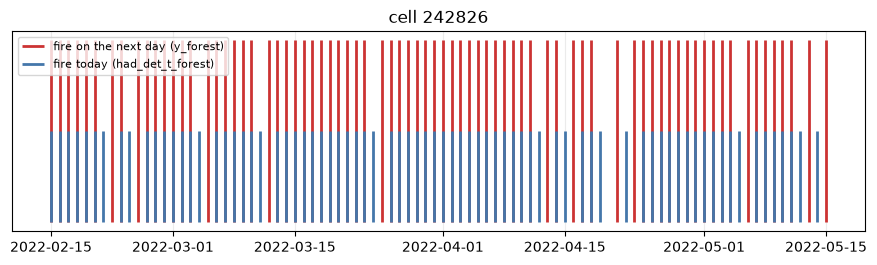

In [6]:
hot = u[u.y_forest == 1].cell_id.value_counts().index[0]
c = rows[(rows.cell_id == hot) & (rows.date_t >= "2022-02-15") & (rows.date_t <= "2022-05-15")].sort_values("date_t")
plt.figure(figsize=(11, 2.6))
plt.vlines(c.date_t[c.y_forest == 1], 0, 1, color="#c33", lw=2, label="fire on the next day (y_forest)")
plt.vlines(c.date_t[c.had_det_t_forest == 1], 0, 0.5, color="#47a", lw=2, label="fire today (had_det_t_forest)"); plt.legend(loc="upper left", fontsize=8); plt.yticks([]); plt.title(f"cell {int(hot)}")
plt.show()

Fire is "sticky": the best clue for tomorrow is a fire today (blue lines come right before red lines). That is why we also report the score only on rows **with no detection today**
(new ignitions), which is the hard and useful case.

## 5. What is missing or weak here

- **A label is a satellite sighting, not the truth.** Clouds and passes make a real fire look like no fire.
- **One day ahead only.** Longer forecasts (3 to 7 days) are not trained.
- **Ambiguous rows are removed**, not predicted. They might be real forest fires we cannot confirm.
- **Fire counts depend on the satellites.** Suomi NPP and NOAA-20 are both used; if one goes down or an orbit shifts, the rate of detections changes.
- **Fire rates differ a lot between states and years** (2021 was a very big year). A model can learn the year, not the weather.